# Integrating four levels of protein structure into one function prediction

**Protein Function Predictor: the integration step**

The four analysis modules each describe a protein at one structural level:

| Level | What the module does | What it tells us about function |
|---|---|---|
| Primary | the final primary pipeline (3.1-fast-local): DIAMOND `--fast` search of Swiss-Prot, HMMER search of Pfam, ESM-2 embedding with nearest-neighbour retrieval, ProtParam, UniProt metadata for the 3 best hits, optional EBI BLASTp and InterProScan, with its own evidence tier (A–D) | *which* characterised protein or family the query is related to, and how closely |
| Secondary | the final secondary pipeline: majority consensus of five single-sequence predictors (S4PRED, ESM-2 SS3, PSIPRED-single, GOR IV, Chou–Fasman), compared with up to three experimental PDB structures | whether the query's local structure matches solved structures of its relatives |
| Tertiary | the AlphaFold DB structure of the primary level's closest Swiss-Prot match: its confidence (pLDDT), Foldseek structural search, and UniProt annotation transfer from the AlphaFold DB match (active, binding and metal sites) | whether that structure matches characterised proteins (Foldseek gives a homology probability) and conserves their functional sites |
| Quaternary | UniProt, Complex Portal, RCSB PDB, PDBe PISA, SWISS-MODEL, IntAct, AlphaFold DB | the oligomeric state and complexes of the related protein |

This notebook turns those four results into **one predicted function with a confidence score**,
and explains every step of how it got there.

**The idea in one line:** function is predicted by *transferring* the annotation of a related,
characterised protein, so the confidence is

$$P(\text{function correct}) = P(\text{query is homologous to the template}) \times P(\text{function is conserved at this evolutionary distance}),$$

after which the structural levels act as **consistency checks** that raise or lower this estimate.

All data in this notebook are real outputs of the four modules (run through the project's web app);
no tool is re-run here, so the notebook runs in seconds and needs no internet.

## 1. Setup
Only `numpy`, `pandas` and `matplotlib` are needed (pre-installed on Kaggle and Colab).

In [1]:
import json
import math
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

Matplotlib is building the font cache; this may take a moment.


## 2. Why not simply add up (or average) the four scores?

A weighted sum treats the four levels as four independent opinions about function. Biologically they are not:

1. **The levels are not independent.** The tertiary level analyses the AlphaFold DB structure of the very protein
   the *sequence* search found; the secondary-structure comparison uses PDB entries found by *sequence* search; the
   quaternary pipeline studies the *sequence* hit itself. Adding their scores counts the same homologue several times.
2. **They answer different questions.** Sequence and structure answer *"is the query related to a known protein?"*.
   Function transfer additionally needs *"if it is related, is the function still the same at this distance?"*.
   Enzymes illustrate this: 40% identity is enough to transfer the first three EC digits confidently, but all four
   digits need more than 60% identity for 90% accuracy (Tian & Skolnick 2003), and function starts to diverge
   below about 70% identity (Rost 2002).
3. **The E-value is a weak guide to function.** Tian & Skolnick found the magnitude of the PSI-BLAST E-value to be only
   weakly correlated with conservation of enzyme function, so this model uses *percent identity* for the
   conservation term and keeps E-values only as significance filters.
4. **Averaging over "whatever ran" inflates weak evidence.** If only one level produced a result, a renormalised
   average gives that one result the full weight (shown concretely in Section 9).

## 3. The model: a chain of evidence

### Step 1: choose the route (what is transferred, and how specific it is)
The first route that applies is used:

| Route | Condition | Predicted function | P(homology) | P(function conserved) |
|---|---|---|---|---|
| **1. Sequence** | the primary notebook's best hit (DIAMOND or EBI BLASTp) passed its homology test (identity ≥ 30%, query coverage ≥ 80%) and is a characterised protein | the hit's protein name (+ its GO molecular functions) | 0.99 if identity ≥ 40%; 0.90 if 30–40% | 0.95 if ≥ 60%; 0.80 if 40–60%; 0.55 if 30–40% |
| **2. Domain** | the primary notebook found domain support: a Pfam domain with independent E-value < 1e-10 (HMMER), otherwise an integrated InterPro entry (InterProScan) | "*X* family member" | 0.95 | 0.50 |
| **3. Fold** | the closest Swiss-Prot match shares the query's fold (it passed the homology test) but is uncharacterised and there is no domain support; its AlphaFold DB structure is reliable (mean pLDDT > 70) and the tertiary notebook transferred the annotation of a characterised AlphaFold DB match *X* (Foldseek prob ≥ 0.5 over ≥ 50% of the structure) | "Structural similarity to *X*" | P(homology to the match) × Foldseek's `prob` | 0.25 |
| none | — | "Function not determined" | — | — |

* The identity cut-offs come from the twilight-zone analysis of sequence alignments (Rost 1999: below ~30–40%
  identity, homology becomes uncertain) and the enzyme-function curves of Tian & Skolnick (2003).
* Foldseek's `prob` is, by its documentation, the *"estimated probability for query and target to be homologous
  (e.g. being within the same SCOPe superfamily)"*. In route 3 two links are chained: the query to the closest
  Swiss-Prot match (sequence, as in route 1), and that protein's structure to *X* (Foldseek), so P(homology) is
  their product.
* The structure is trusted only above a mean pLDDT of 70, AlphaFold's own threshold for a confident prediction
  (Jumper et al. 2021) and the tertiary notebook's boundary between *moderate* and *LOW* confidence. Proteins with
  at least 30% identity over most of their length share their fold (Rost 1999), which is why route 3 asks the
  match to have passed the homology test.
* A shared fold without other evidence of common ancestry is rarely associated with a shared interaction
  (Aloy et al. 2003), and similar folds often carry different functions, so the fold route stays low.
* Every prediction states its **specificity**: specific protein, protein family, or fold only.
* Routes 1 and 2 use the primary notebook's own decisions (its `strong_homology` and `domain_support`, the inputs of
  its evidence tier), so the two notebooks cannot disagree about what passed. When domain support comes only from
  InterProScan, the family is the InterPro entry that integrates a Pfam signature, otherwise the one most member
  databases agree on.

### Step 2: consistency checks (Bayesian updating on the log-odds scale)
Starting from $\text{logit}(P_\text{base})$, each other level adds a log-likelihood-ratio-like adjustment:

| Check | Agrees | Contradicts |
|---|---|---|
| Secondary: agreement of the consensus with experimental PDB structures (≥ 20 comparable residues) | ≥ 75%: +0.4 | < 60%: −1.0 |
| Quaternary: the template's assembly evidence | CONFIRMED / SUPPORTED: +0.4 | CONFLICTING: −0.5 |

* **Agreement is rewarded less than contradiction is penalised, on purpose.** If the query really is homologous
  to the template, agreement is *expected* (and these checks partly reuse the same template), so it carries
  little new information; disagreement is surprising and therefore informative.
* The secondary thresholds follow from predictor accuracy: three-state predictors are right for roughly 80% of
  residues, so a shared fold should give about 75% agreement or more.
* Close homologues (≥ 30–40% identity) almost invariably interact in the same way (Aloy et al. 2003); below 40%
  identity the quaternary adjustment is therefore halved.
* **The tertiary level gives no adjustment.** It analyses the AlphaFold DB structure of the primary level's own
  match, so a structural agreement would count the template a second time, and a structural novelty of the template
  says nothing against transferring the template's function. Its contribution is route 3 (when the match is
  uncharacterised) and the context it reports: confidence (pLDDT), structural matches and conserved sites.

Final score $= \sigma\big(\text{logit}(P_\text{base}) + \sum \Delta\big)$. Bands: **high ≥ 0.80**, **moderate ≥ 0.50**, low below.
The score is a literature-anchored estimate, *not* a calibrated probability (see Section 12).

## 4. Reading the four modules' outputs
The functions below read the results exactly as the web app stores them (one `LevelResult` per level) and keep
only the evidence the model needs. They are also used in Section 5b to load new proteins downloaded from the app.

In [2]:
import math
import re

GENERIC_GO = {
    "protein binding", "identical protein binding", "enzyme binding",
    "protein homodimerization activity", "protein heterodimerization activity", "molecular_function",
}
UNCHARACTERISED = re.compile(r"^(putative\s+)?(uncharacteri[sz]ed|UPF\d+)\b", re.IGNORECASE)


def _num(value):
    """A finite number, or None."""
    try:
        number = float(value)
    except (TypeError, ValueError):
        return None
    return number if math.isfinite(number) else None


def _live(level):
    return isinstance(level, dict) and level.get("source") == "live"


def _swissprot_title(title, hit_id):
    """A Swiss-Prot title -> (protein, organism, gene).

    DIAMOND titles start with the identifier ('sp|P69905|HBA_HUMAN Hemoglobin subunit alpha OS=...'),
    EBI BLAST descriptions do not ('Hemoglobin subunit alpha OS=Homo sapiens OX=9606 ...').
    """
    text = str(title or "").strip()
    first, _, rest = text.partition(" ")
    if (hit_id and first == hit_id) or "|" in first:
        text = rest
    organism = re.search(r"OS=(.*?)(?: OX=| GN=| PE=| SV=|$)", text)
    gene = re.search(r" GN=(\S+)", text)
    return text.split(" OS=")[0].strip(), organism.group(1).strip() if organism else "", gene.group(1) if gene else ""


def _entry_name(hit_id, accession):
    """'sp|P69905|HBA_HUMAN' or 'SP:HBA_HUMAN' -> 'HBA_HUMAN'."""
    text = str(hit_id or "").strip()
    if "|" in text:
        parts = text.split("|")
        return parts[2] if len(parts) > 2 and parts[2] else parts[-1]
    return text.split(":")[-1] if text else accession


def _dict(value):
    return value if isinstance(value, dict) else {}


def _interpro_family(architecture):
    """The InterPro entry for a family-level prediction: one that integrates a Pfam signature
    if there is one, otherwise the entry most member databases agree on (then the longest)."""
    rows = [r for r in architecture or [] if isinstance(r, dict) and r.get("interpro_accession") and r.get("description")]
    if not rows:
        return None

    def rank(r):
        members = [m.strip() for m in str(r.get("members") or "").split(",") if m.strip()]
        return ("Pfam" in members, len(members), (_num(r.get("end")) or 0) - (_num(r.get("start")) or 0))

    return max(rows, key=rank)


def primary_evidence(level):
    """The primary notebook's own evidence summary: its best homology hit and its domain support."""
    if not _live(level):
        return {"ran": False}
    raw = _dict(level.get("raw"))
    summary = _dict(raw.get("evidence_summary"))
    assessment = _dict(summary.get("assessment"))
    threshold = _num(_dict(raw.get("thresholds")).get("hmmer_evalue")) or 1e-10
    best = _dict(assessment.get("best_hit"))
    identity, coverage = _num(best.get("identity_percent")), _num(best.get("query_coverage_percent_approx"))
    hit = None
    if best.get("accession") and identity is not None and coverage is not None:
        accession = str(best["accession"])
        candidate = next((c for c in summary.get("top_homology_candidates") or []
                          if isinstance(c, dict) and c.get("accession") == accession), {})
        protein, organism, gene = _swissprot_title(best.get("title"), best.get("hit_id"))
        if candidate.get("protein_name") and candidate["protein_name"] != best.get("title"):
            protein = str(candidate["protein_name"])  # UniProt's recommended name
        entry = _entry_name(best.get("hit_id"), accession)
        hit = {
            "accession": accession, "entry": entry,
            "protein": protein or entry, "organism": candidate.get("organism") or organism,
            "gene": candidate.get("gene_name") or gene, "method": best.get("method") or "",
            "identity": identity, "coverage": coverage, "evalue": _num(best.get("evalue")),
            "passed": assessment.get("strong_homology") is True,  # >= 30% identity and >= 80% query coverage
            "function": candidate.get("function_annotation") or None,  # UniProt's curated FUNCTION text
        }
    domain = None
    if assessment.get("domain_support") is True:  # Pfam E < 1e-10, or an integrated InterPro entry
        best_domain = _dict(assessment.get("best_domain"))
        evalue = _num(best_domain.get("domain_i_evalue"))
        if evalue is not None and evalue < threshold and best_domain.get("pfam_name"):
            domain = {
                "source": "Pfam", "name": str(best_domain["pfam_name"]),
                "accession": str(best_domain.get("pfam_accession_base") or best_domain.get("pfam_accession") or ""),
                "description": str(best_domain.get("description") or best_domain["pfam_name"]), "evalue": evalue,
            }
        else:
            entry = _interpro_family(summary.get("domain_architecture"))
            if entry is not None:
                domain = {
                    "source": "InterPro", "name": str(entry["interpro_accession"]),
                    "accession": str(entry["interpro_accession"]), "description": str(entry["description"]),
                    "evalue": None,
                }
    tier = assessment.get("tier")
    return {"ran": True, "hit": hit, "domain": domain, "tier": tier if isinstance(tier, str) else None}


def secondary_evidence(level):
    """Best agreement between the predicted secondary structure and experimental PDB structures.

    The final secondary notebook's compare_pdb_references (raw["pdb_references"], filled in by the
    level's background step; "pending" until then). Results of the earlier JPred/ProtBert notebook
    (raw["experimental_comparison"]) are still read, so older saved analyses keep their check.
    """
    if not _live(level):
        return {"ran": False}
    raw = level.get("raw") or {}
    pdb = raw.get("pdb_references")
    if isinstance(pdb, dict):
        status = str(pdb.get("status"))
        rows = [
            {"entity": r.get("PDB_entity"), "identity": r.get("Aligned_identity_pct"),
             "residues": r.get("Comparable_residues"), "agreement": r.get("SS_agreement_pct")}
            for r in pdb.get("rows") or [] if r.get("Status") == "OK"
        ]
    else:  # the earlier notebook's format
        status = "success"
        rows = [
            {"entity": r.get("PDB_entity"), "identity": r.get("Sequence_Identity_%"),
             "residues": r.get("Comparable_Residues"), "agreement": r.get("SS_Agreement_%")}
            for r in raw.get("experimental_comparison") or []
        ]
    rows = [r for r in rows if _num(r["agreement"]) is not None and _num(r["residues"]) is not None]
    best = max(rows, key=lambda r: (float(r["residues"]) >= 20, float(r["agreement"]))) if rows else None
    return {
        "ran": True,
        "pdb_status": status,  # success, pending (background step not finished), unavailable or off
        "best": None if best is None else {
            "entity": str(best["entity"]), "identity": _num(best["identity"]),
            "residues": int(float(best["residues"])), "agreement": float(best["agreement"]),
        },
    }


def _pretty_target(database, token):
    alphafold = re.match(r"^AF-([A-Za-z0-9]+)-F\d+", token)
    pdb = re.match(r"^([0-9][A-Za-z0-9]{3})(?:[-_.]|$)", token)
    if alphafold:
        return f"AlphaFold DB {alphafold.group(1)}"
    if pdb and database.lower().startswith("pdb"):
        chain = token.rsplit("_", 1)[1] if "_" in token else ""
        return f"PDB {pdb.group(1).upper()}" + (f" chain {chain}" if chain else "")
    return token


def tertiary_evidence(level):
    """The tertiary notebook's findings on the AlphaFold DB structure of the primary level's match."""
    if not _live(level):
        return {"ran": False}
    raw = _dict(level.get("raw"))
    template = _dict(raw.get("template"))
    structure = _dict(raw.get("structure"))
    transfer = _dict(raw.get("annotation_transfer"))
    best = None
    hit = _dict(raw.get("best_hit"))
    if hit.get("target"):
        token, _, description = str(hit["target"]).partition(" ")
        database = next((str(db) for db, h in _dict(raw.get("foldseek_top_hits")).items()
                         if _dict(h).get("target") == hit["target"]), "")
        best = {"database": database, "target": _pretty_target(database, token), "description": description.strip(),
                "evalue": _num(hit.get("eval")), "prob": _num(hit.get("prob")), "coverage": _num(hit.get("coverage"))}
    neighbour = None
    annotation, afdb = _dict(transfer.get("annotation")), _dict(transfer.get("afdb_hit"))
    if transfer.get("status") == "transferred" and annotation.get("accession"):
        sites = [site for site in annotation.get("sites") or [] if isinstance(site, dict)]
        description = str(afdb.get("target", "")).partition(" ")[2].strip()
        name = annotation.get("name")
        neighbour = {
            "accession": str(annotation["accession"]),
            "name": str(name) if name and name != "n/a" else description or str(annotation["accession"]),
            "function": str(annotation["function"]) if annotation.get("function") else None,
            "prob": _num(afdb.get("prob")), "coverage": _num(afdb.get("coverage")), "evalue": _num(afdb.get("eval")),
            "sites": len(sites), "conserved": sum(1 for site in sites if site.get("conserved") is True),
        }
    identity = _num(template.get("identity"))
    return {
        "ran": True,
        "template": str(template.get("accession") or raw.get("uniprot_id") or ""),
        "template_identity": identity,
        "template_coverage": _num(template.get("coverage")),
        # The structure shares the query's fold: its protein passed the primary homology test.
        "template_passed": template.get("passed") is True and identity is not None,
        "plddt": _num(structure.get("mean_plddt")),
        "experimental": structure.get("has_plddt") is False,
        "best": best,
        "neighbour": neighbour,  # the characterised AlphaFold DB match whose annotation was transferred
    }


def quaternary_evidence(level):
    """What the quaternary pipeline found for the analysed protein (assembly, complexes, GO terms)."""
    if not _live(level):
        return {"ran": False}
    raw = level.get("raw") or {}
    output = raw.get("pipeline_output") or {}
    assembly = output.get("target_self_assembly") or {}
    go_terms = []
    for term in (raw.get("uniprot") or {}).get("go_terms", []) or []:
        aspect, _, name = str(term.get("name", "")).partition(":")
        if aspect == "F" and name and name.lower() not in GENERIC_GO:
            go_terms.append([str(term.get("id")), name])
    go_terms.sort(key=lambda t: "activity" not in t[1].lower())  # activities first
    return {
        "ran": True,
        "mode": raw.get("input"),  # "homologue" or "sequence"
        "analysed": raw.get("analysed_target"),
        "status": str(assembly.get("confidence_status") or output.get("status") or "UNKNOWN"),
        "formula": assembly.get("formula"),
        "assembly_type": assembly.get("assembly_type"),
        "subunits": assembly.get("subunit_count"),
        "complexes": [[c.get("name"), c.get("complex_portal_id"), c.get("stoichiometry")]
                      for c in output.get("functional_complexes") or []],
        "go_mf": go_terms,
    }


def evidence_from_levels(levels):
    """levels: {'primary': LevelResult dict or None, 'secondary': ..., 'tertiary': ..., 'quaternary': ...}"""
    return {
        "primary": primary_evidence(levels.get("primary")),
        "secondary": secondary_evidence(levels.get("secondary")),
        "tertiary": tertiary_evidence(levels.get("tertiary")),
        "quaternary": quaternary_evidence(levels.get("quaternary")),
    }

## 5. The data: real outputs of the four modules

Eight proteins analysed with the project's web app (results cached by the app, November 2026). They were chosen
to cover every route of the model, and some deliberately lack levels, to show how missing evidence is handled.
The primary results are the app's cached DIAMOND and HMMER outputs expressed in the final primary notebook's format
(pipeline 3.1-fast-local, local modules only, so `function` - UniProt's curated text - is empty and every hit was
found by DIAMOND). Those searches were run by an earlier version of the primary pipeline, before the final notebook
made DIAMOND `--fast` its default; the notebook's own benchmark found `--fast` and `--sensitive` give the same top
hit, identity, coverage and tier for all eight of its test cases (down to ~30% identity). The integration only uses
the top hit, its identity and coverage, and the primary notebook's two decisions (strong homology, domain support),
whose rules are unchanged:

| Protein | Levels available | Why it is included |
|---|---|---|
| Hemoglobin α | all four | well-characterised protein, oligomeric (α2β2) |
| Ubiquitin | all four | well-characterised monomer |
| SNRPG-like peptide B | primary, secondary | close homologue (78%), plus a secondary-structure check |
| SNRPG-like peptide A | primary | the same family without the secondary check (compare with B) |
| AIG1-like protein | primary | homology test failed (37%, coverage 59%) but a Pfam domain passed |
| Unknown sequence | primary, secondary | no relatives anywhere: should stay undetermined (the tertiary level is skipped: there is no UniProt ID) |
| Cytochrome c | tertiary only | the tertiary notebook's own example: UniProt ID P99999 given directly, without the primary level |

The tertiary results are those of the integrated tertiary notebook (AlphaFold DB structure of a UniProt entry).
Its recorded example is cytochrome c (P99999: mean pLDDT 97.9, best Foldseek match AF-A0A1S3FTQ6, "Cytochrome c,
somatic", probability 1.00, annotation transferred with the function shown in the notebook, cut at 300 characters
as printed there). The earlier tertiary results of the other proteins came from a SWISS-MODEL model of the query and
are not comparable, so their tertiary level is marked as not run.

The secondary results here were produced by the earlier secondary notebook (JPred + ProtBert consensus, compared
with up to ten PDB structures, coil included). The final secondary notebook uses a five-predictor majority consensus
and compares it with up to three PDB structures on the residues PDBe annotates as helix or strand; the extraction code
above reads both formats, so results exported from the app with the final pipeline can be added in the next cell.

The quaternary results are those of the team's quaternary pipeline: hemoglobin α (P69905: homotetramer A4,
CONFIRMED by PDBe PISA on PDB 1A01, Complex Portal CPX-2158) and ubiquitin (closest Swiss-Prot entry Q865C5:
monomer, SUPPORTED).

In [3]:
EVIDENCE = json.loads(r'''
[
 {
  "name": "Hemoglobin α",
  "note": "app example, UniProt P69905",
  "length": 142,
  "primary": {
   "ran": true,
   "hit": {
    "accession": "P69905",
    "entry": "HBA_HUMAN",
    "protein": "Hemoglobin subunit alpha",
    "organism": "Homo sapiens",
    "gene": "HBA1",
    "method": "DIAMOND (local)",
    "identity": 100.0,
    "coverage": 100.0,
    "evalue": 2.94e-100,
    "passed": true,
    "function": null
   },
   "domain": {
    "source": "Pfam",
    "name": "Globin",
    "accession": "PF00042",
    "description": "Globin",
    "evalue": 2.9e-33
   },
   "tier": "A - Strong"
  },
  "secondary": {
   "ran": true,
   "pdb_status": "success",
   "best": {
    "entity": "1BZ1_1",
    "identity": 100.0,
    "residues": 125,
    "agreement": 96.8
   }
  },
  "tertiary": {
   "ran": false
  },
  "quaternary": {
   "ran": true,
   "mode": "homologue",
   "analysed": "P69905",
   "status": "CONFIRMED",
   "formula": "A4",
   "assembly_type": "HOMOMER",
   "subunits": 4,
   "complexes": [
    [
     "Hemoglobin HbA complex",
     "CPX-2158",
     "A2B2"
    ]
   ],
   "go_mf": [
    [
     "GO:0005344",
     "oxygen carrier activity"
    ],
    [
     "GO:0020037",
     "heme binding"
    ],
    [
     "GO:0005506",
     "iron ion binding"
    ],
    [
     "GO:0019825",
     "oxygen binding"
    ]
   ]
  }
 },
 {
  "name": "Ubiquitin",
  "note": "app example, PDB 1UBQ",
  "length": 76,
  "primary": {
   "ran": true,
   "hit": {
    "accession": "Q865C5",
    "entry": "UBIQ_CAMDR",
    "protein": "Ubiquitin",
    "organism": "Camelus dromedarius",
    "gene": "",
    "method": "DIAMOND (local)",
    "identity": 100.0,
    "coverage": 100.0,
    "evalue": 2.36e-48,
    "passed": true,
    "function": null
   },
   "domain": {
    "source": "Pfam",
    "name": "ubiquitin",
    "accession": "PF00240",
    "description": "Ubiquitin family",
    "evalue": 7.7e-34
   },
   "tier": "A - Strong"
  },
  "secondary": {
   "ran": true,
   "pdb_status": "success",
   "best": {
    "entity": "1FXT_2",
    "identity": 100.0,
    "residues": 57,
    "agreement": 98.24561403508771
   }
  },
  "tertiary": {
   "ran": false
  },
  "quaternary": {
   "ran": true,
   "mode": "homologue",
   "analysed": "Q865C5",
   "status": "SUPPORTED",
   "formula": "A",
   "assembly_type": "MONOMER",
   "subunits": 1,
   "complexes": [],
   "go_mf": []
  }
 },
 {
  "name": "SNRPG-like peptide B",
  "note": "test sequence, 53 aa",
  "length": 53,
  "primary": {
   "ran": true,
   "hit": {
    "accession": "Q3ZBL0",
    "entry": "RUXG_BOVIN",
    "protein": "Small nuclear ribonucleoprotein G",
    "organism": "Bos taurus",
    "gene": "SNRPG",
    "method": "DIAMOND (local)",
    "identity": 78.0,
    "coverage": 94.34,
    "evalue": 7.48e-21,
    "passed": true,
    "function": null
   },
   "domain": {
    "source": "Pfam",
    "name": "LSM",
    "accession": "PF01423",
    "description": "LSM domain",
    "evalue": 1e-11
   },
   "tier": "B - Probable"
  },
  "secondary": {
   "ran": true,
   "pdb_status": "success",
   "best": {
    "entity": "4V98_8",
    "identity": 75.47169811320755,
    "residues": 40,
    "agreement": 92.5
   }
  },
  "tertiary": {
   "ran": false
  },
  "quaternary": {
   "ran": false
  }
 },
 {
  "name": "SNRPG-like peptide A",
  "note": "test sequence, 50 aa",
  "length": 50,
  "primary": {
   "ran": true,
   "hit": {
    "accession": "Q3ZBL0",
    "entry": "RUXG_BOVIN",
    "protein": "Small nuclear ribonucleoprotein G",
    "organism": "Bos taurus",
    "gene": "SNRPG",
    "method": "DIAMOND (local)",
    "identity": 78.0,
    "coverage": 100.0,
    "evalue": 9.35e-21,
    "passed": true,
    "function": null
   },
   "domain": {
    "source": "Pfam",
    "name": "LSM",
    "accession": "PF01423",
    "description": "LSM domain",
    "evalue": 9.7e-12
   },
   "tier": "B - Probable"
  },
  "secondary": {
   "ran": false
  },
  "tertiary": {
   "ran": false
  },
  "quaternary": {
   "ran": false
  }
 },
 {
  "name": "AIG1-like protein",
  "note": "test sequence, 184 aa",
  "length": 184,
  "primary": {
   "ran": true,
   "hit": {
    "accession": "Q9D8B1",
    "entry": "AIG1_MOUSE",
    "protein": "Androgen-induced gene 1 protein",
    "organism": "Mus musculus",
    "gene": "Aig1",
    "method": "DIAMOND (local)",
    "identity": 37.1,
    "coverage": 59.24,
    "evalue": 4.98e-19,
    "passed": false,
    "function": null
   },
   "domain": {
    "source": "Pfam",
    "name": "Far-17a_AIG1",
    "accession": "PF04750",
    "description": "FAR-17a/AIG1-like protein",
    "evalue": 2.1e-31
   },
   "tier": "C - Partial (family/domain-level hypothesis)"
  },
  "secondary": {
   "ran": false
  },
  "tertiary": {
   "ran": false
  },
  "quaternary": {
   "ran": false
  }
 },
 {
  "name": "Unknown sequence",
  "note": "test sequence with no known relatives, 55 aa",
  "length": 55,
  "primary": {
   "ran": true,
   "hit": null,
   "domain": null,
   "tier": "D - Inconclusive / uncharacterised"
  },
  "secondary": {
   "ran": true,
   "pdb_status": "success",
   "best": null
  },
  "tertiary": {
   "ran": false
  },
  "quaternary": {
   "ran": false
  }
 },
 {
  "name": "Cytochrome c",
  "note": "the tertiary notebook's example (UniProt P99999), 105 aa",
  "length": 105,
  "primary": {
   "ran": false
  },
  "secondary": {
   "ran": false
  },
  "tertiary": {
   "ran": true,
   "template": "P99999",
   "template_identity": null,
   "template_coverage": null,
   "template_passed": false,
   "plddt": 97.9,
   "experimental": false,
   "best": {
    "database": "afdb50",
    "target": "AlphaFold DB A0A1S3FTQ6",
    "description": "Cytochrome c, somatic",
    "evalue": 4.679e-21,
    "prob": 1.0,
    "coverage": 1.0
   },
   "neighbour": {
    "accession": "A0A1S3FTQ6",
    "name": "Cytochrome c, somatic",
    "function": "Electron carrier protein. The oxidized form of the cytochrome c heme group can accept an electron from the heme group of the cytochrome c1 subunit of cytochrome reductase. Cytochrome c then transfers this electron to the cytochrome oxidase complex, the final protein carrier in the mitochondrial elec",
    "prob": 1.0,
    "coverage": 1.0,
    "evalue": 4.679e-21,
    "sites": 0,
    "conserved": 0
   }
  },
  "quaternary": {
   "ran": false
  }
 }
]
''')
print(f"{len(EVIDENCE)} proteins loaded:", ", ".join(p['name'] for p in EVIDENCE))

7 proteins loaded: Hemoglobin α, Ubiquitin, SNRPG-like peptide B, SNRPG-like peptide A, AIG1-like protein, Unknown sequence, Cytochrome c


### 5b. Optional: add your own proteins
In the web app, open a finished analysis and click **Download JSON**. Add the downloaded `.json` files to this
notebook (Kaggle: *Add Input* → upload them as a dataset; Colab: upload them into a folder called `analyses`).
The cell below finds them automatically; with no files it does nothing.

In [4]:
def evidence_from_app_download(path):
    job = json.loads(Path(path).read_text(encoding="utf-8"))
    levels = {level["key"]: (level.get("result") if level.get("status") == "completed" else None) for level in job["levels"]}
    return {"name": job["query"]["name"], "note": f"downloaded from the app ({Path(path).name})",
            "length": job["query"]["length"], **evidence_from_levels(levels)}

added = []
for folder in (Path("/kaggle/input"), Path("analyses")):
    if folder.is_dir():
        for path in sorted(folder.rglob("*.json")):
            try:
                added.append(evidence_from_app_download(path))
            except (KeyError, TypeError, ValueError, AttributeError) as error:
                print(f"Skipped {path.name}: not an analysis downloaded from the app ({error.__class__.__name__})")
EVIDENCE.extend(added)
print(f"Added {len(added)} protein(s); {len(EVIDENCE)} in total.")

Added 0 protein(s); 7 in total.


### What each level found

In [5]:
def overview_row(p):
    prim, sec, ter, quat = p["primary"], p["secondary"], p["tertiary"], p["quaternary"]
    hit = prim.get("hit") if prim["ran"] else None
    dom = prim.get("domain") if prim["ran"] else None
    best_ss = sec.get("best") if sec["ran"] else None
    best_fs = ter.get("best") if ter["ran"] else None
    return {
        "Protein": p["name"],
        "Swiss-Prot hit (identity / coverage)": ("not run" if not prim["ran"] else "none" if hit is None else
            f"{hit['entry']} ({hit['identity']:.1f}% / {hit['coverage']:.1f}%){'' if hit['passed'] else ' - failed'}"),
        "Domain support": "not run" if not prim["ran"] else (
            "none" if not dom else f"{dom['name']} (E={dom['evalue']:.1e})" if dom.get("evalue") is not None
            else f"{dom['description']} ({dom['accession']})"),
        "Primary tier": "not run" if not prim["ran"] else prim.get("tier") or "-",
        "SS agreement with PDB": "not run" if not sec["ran"] else (f"{best_ss['agreement']:.1f}% ({best_ss['entity']})" if best_ss else "no structure"),
        "AlphaFold DB structure (pLDDT)": "not run" if not ter["ran"] else f"{ter['template']} ({ter['plddt']})",
        "Foldseek best (prob)": "not run" if not ter["ran"] else (
            f"{best_fs['target']} ({best_fs['prob']})" if best_fs else "none"),
        "Annotation transferred from": "not run" if not ter["ran"] else (
            f"{ter['neighbour']['accession']} ({ter['neighbour']['name']})" if ter.get("neighbour") else "none"),
        "Quaternary": "not run" if not quat["ran"] else f"{quat['analysed']}: {quat['formula']} {quat['status']}",
    }

display(pd.DataFrame([overview_row(p) for p in EVIDENCE]).set_index("Protein"))

,Swiss-Prot hit (identity / coverage),Domain support,Primary tier,SS agreement with PDB,AlphaFold DB structure (pLDDT),Foldseek best (prob),Annotation transferred from,Quaternary
Protein,,,,,,,,
Hemoglobin α,HBA_HUMAN (100.0% / 100.0%),Globin (E=2.9e-33),A - Strong,96.8% (1BZ1_1),not run,not run,not run,P69905: A4 CONFIRMED
Ubiquitin,UBIQ_CAMDR (100.0% / 100.0%),ubiquitin (E=7.7e-34),A - Strong,98.2% (1FXT_2),not run,not run,not run,Q865C5: A SUPPORTED
SNRPG-like peptide B,RUXG_BOVIN (78.0% / 94.3%),LSM (E=1.0e-11),B - Probable,92.5% (4V98_8),not run,not run,not run,not run
SNRPG-like peptide A,RUXG_BOVIN (78.0% / 100.0%),LSM (E=9.7e-12),B - Probable,not run,not run,not run,not run,not run
AIG1-like protein,AIG1_MOUSE (37.1% / 59.2%) - failed,Far-17a_AIG1 (E=2.1e-31),C - Partial (family/domain-level hypothesis),not run,not run,not run,not run,not run
Unknown sequence,none,none,D - Inconclusive / uncharacterised,no structure,not run,not run,not run,not run
Cytochrome c,not run,not run,not run,not run,P99999 (97.9),AlphaFold DB A0A1S3FTQ6 (1.0),"A0A1S3FTQ6 (Cytochrome c, somatic)",not run


## 6. The model in code
All numbers live in one dictionary, `PARAMS`, so they can be inspected and varied (Section 10).

In [6]:
PARAMS = {
    # Route 1 - sequence homology (the primary notebook's best hit, DIAMOND or EBI BLASTp, that passed its thresholds)
    "seq_hom_40": 0.99,       # P(homologous) when identity >= 40%
    "seq_hom_30": 0.90,       # P(homologous) when identity is 30-40% (twilight zone, Rost 1999)
    "cons_60": 0.95,          # P(function conserved) at >= 60% identity (Tian & Skolnick 2003)
    "cons_40": 0.80,          # ... at 40-60% identity (first three EC digits reliable)
    "cons_30": 0.55,          # ... at 30-40% identity (function diverges, Rost 2002)
    # Route 2 - domain support (Pfam domain with independent E-value < 1e-10, else an integrated InterPro entry)
    "dom_hom": 0.95,          # P(the domain is a true family member)
    "dom_cons": 0.50,         # P(the family's function applies to this protein)
    # Route 3 - fold only (tertiary: Foldseek match of the AlphaFold DB structure of the primary level's match)
    "fold_cons": 0.25,        # P(function conserved | same fold only) (Aloy et al. 2003)
    "fold_prob": 0.5,         # the structural match counts if Foldseek's homology probability >= this ...
    "fold_cov": 0.5,          # ... over >= this fraction of the structure (both from the tertiary notebook)
    "plddt_min": 70.0,        # the structure is trusted only if its mean pLDDT is above this (AlphaFold "confident")
    # Consistency checks (log-odds adjustments)
    "ss_agree": 75.0,         # % agreement with experimental structures that counts as agreement
    "ss_contra": 60.0,        # % agreement below which it counts as a contradiction
    "ss_min_res": 20,         # minimum residues compared
    "d_ss_agree": 0.4,
    "d_ss_contra": -1.0,
    "d_q_good": 0.4,          # template's assembly CONFIRMED or SUPPORTED
    "d_q_conflict": -0.5,     # template's assembly evidence CONFLICTING
    "q_full_identity": 40.0,  # below this identity the quaternary adjustment is halved (Aloy et al. 2003)
    # Confidence bands
    "high": 0.80,
    "moderate": 0.50,
}


def logit(p):
    p = min(max(p, 1e-3), 1 - 1e-3)
    return math.log(p / (1 - p))


def sigmoid(x):
    return 1 / (1 + math.exp(-x))


def p_homology_seq(identity, P):
    return P["seq_hom_40"] if identity >= 40 else P["seq_hom_30"]


def p_conserved_seq(identity, P):
    if identity >= 60:
        return P["cons_60"]
    if identity >= 40:
        return P["cons_40"]
    return P["cons_30"]


def fold_is_significant(tertiary, P):
    """The tertiary level transferred the annotation of a characterised structural match."""
    match = tertiary.get("neighbour") if tertiary.get("ran") else None
    return (bool(match) and bool(match["function"]) and not UNCHARACTERISED.match(match["name"])
            and match["prob"] is not None and match["prob"] >= P["fold_prob"]
            and match["coverage"] is not None and match["coverage"] >= P["fold_cov"])


def model_is_reliable(tertiary, P):
    """The structure is trusted: an experimental structure, or mean pLDDT above plddt_min."""
    if not tertiary.get("ran"):
        return False
    return tertiary.get("experimental") is True or (tertiary.get("plddt") is not None and tertiary["plddt"] > P["plddt_min"])


def family_label(description):
    lowered = description.lower()
    if lowered.endswith("family"):
        return f"{description} member"
    if lowered.endswith("domain"):
        return f"{description}-containing protein"
    return f"{description} family"


def predict(ev, P=PARAMS):
    """Chain of evidence: P(homology) x P(function conserved), then consistency checks in log-odds."""
    prim, sec, ter, quat = ev["primary"], ev["secondary"], ev["tertiary"], ev["quaternary"]
    hit = prim.get("hit") if prim.get("ran") else None
    domain = prim.get("domain") if prim.get("ran") else None
    named = hit is not None and hit["passed"] and not UNCHARACTERISED.match(hit["protein"] or hit["entry"])

    # ---- Step 1: choose the route (what is transferred, and how specific it is)
    if named:
        route, specificity = "sequence", "specific protein"
        function = hit["protein"]
        p_hom, p_cons = p_homology_seq(hit["identity"], P), p_conserved_seq(hit["identity"], P)
        basis = (f"closest Swiss-Prot protein {hit['accession']} ({hit['entry']}), "
                 f"{hit['identity']:.1f}% identity over {hit['coverage']:.1f}% of the query")
    elif domain is not None:
        route, specificity = "domain", "protein family"
        source = domain.get("source", "Pfam")
        function = f"{family_label(domain['description'])} ({source} {domain['accession']})"
        p_hom, p_cons = P["dom_hom"], P["dom_cons"]
        if domain.get("evalue") is not None:
            basis = f"{source} domain {domain['description']} ({domain['accession']}, E = {domain['evalue']:.1e})"
        else:
            basis = f"{source} entry {domain['description']} ({domain['accession']}, integrated InterProScan signatures)"
    elif (prim.get("ran") and ter.get("ran") and ter.get("template_passed")
          and model_is_reliable(ter, P) and fold_is_significant(ter, P)):
        match = ter["neighbour"]
        route, specificity = "fold", "fold only"
        function = f"Structural similarity to {match['name']} ({match['accession']})"
        # query ~ the structure's protein (sequence homology), then that structure ~ the match (Foldseek)
        p_hom, p_cons = p_homology_seq(ter["template_identity"], P) * match["prob"], P["fold_cons"]
        basis = (f"Foldseek match of the AlphaFold DB structure of {ter['template']} "
                 f"({ter['template_identity']:.1f}% identical to the query) to {match['accession']} "
                 f"(prob = {match['prob']:.2f}, coverage {match['coverage']:.0%})")
    else:
        route, specificity, function, p_hom, p_cons, basis = None, "none", "Function not determined", None, None, ""

    support = {key: ("not run" if not ev[key].get("ran") else "neutral") for key in ("primary", "secondary", "tertiary", "quaternary")}
    steps = []
    if route is None:
        return {"function": function, "route": None, "specificity": specificity, "score": None,
                "band": "undetermined", "steps": steps, "support": support, "basis": basis,
                "p_hom": None, "p_cons": None, "base": None}

    base = p_hom * p_cons
    total = logit(base)
    steps.append(("base", f"P(homology) {p_hom:.2f} x P(function conserved) {p_cons:.2f} = {base:.2f}", total))
    if route in ("sequence", "domain"):
        support["primary"] = "supports"
    else:
        support["tertiary"] = "supports"

    # ---- Step 2: consistency checks
    if route != "fold" and ter.get("ran"):
        # The structure is that of the primary level's own match, so it cannot test the transfer.
        steps.append(("tertiary", f"it analysed the AlphaFold DB structure of {ter.get('template') or 'the primary match'}, "
                                  "the primary level's own match, so it is not an independent test", 0.0))

    if sec.get("ran"):
        best = sec.get("best")
        if sec.get("pdb_status") == "pending":
            steps.append(("secondary", "the comparison with experimental PDB structures has not finished", 0.0))
        elif sec.get("pdb_status") == "unavailable":
            steps.append(("secondary", "the PDB reference lookup was unavailable", 0.0))
        elif best is None or best["residues"] < P["ss_min_res"]:
            steps.append(("secondary", "no experimental structure to compare with", 0.0))
        elif best["agreement"] >= P["ss_agree"]:
            steps.append(("secondary", f"{best['agreement']:.1f}% agreement with {best['entity']} ({best['residues']} residues)", P["d_ss_agree"]))
            support["secondary"] = "supports"
        elif best["agreement"] < P["ss_contra"]:
            steps.append(("secondary", f"only {best['agreement']:.1f}% agreement with {best['entity']}", P["d_ss_contra"]))
            support["secondary"] = "contradicts"
        else:
            steps.append(("secondary", f"{best['agreement']:.1f}% agreement with {best['entity']} (inconclusive)", 0.0))

    if quat.get("ran"):
        about_template = route == "sequence" and quat.get("mode") == "homologue" and quat.get("analysed") == hit["accession"]
        if not about_template:
            steps.append(("quaternary", "the pipeline did not analyse the predicted template", 0.0))
        else:
            factor = 1.0 if hit["identity"] >= P["q_full_identity"] else 0.5
            status = quat["status"]
            if status in ("CONFIRMED", "SUPPORTED"):
                steps.append(("quaternary", f"template assembly {quat['formula']} is {status}", P["d_q_good"] * factor))
                support["quaternary"] = "supports"
            elif status == "CONFLICTING":
                steps.append(("quaternary", "template assembly evidence is CONFLICTING", P["d_q_conflict"] * factor))
                support["quaternary"] = "contradicts"
            else:
                steps.append(("quaternary", f"template assembly status {status} (no adjustment)", 0.0))

    total = sum(delta for _, _, delta in steps)
    score = sigmoid(total)
    band = "high" if score >= P["high"] else "moderate" if score >= P["moderate"] else "low"
    return {"function": function, "route": route, "specificity": specificity, "score": score, "band": band,
            "steps": steps, "support": support, "basis": basis, "p_hom": p_hom, "p_cons": p_cons, "base": base}

## 7. The base confidence as a function of sequence identity
For the sequence route, the starting confidence is P(homology) × P(function conserved). The steps sit at the
literature thresholds: 30% (primary test), 40% (three EC digits, Tian & Skolnick) and 60% (all four EC digits).

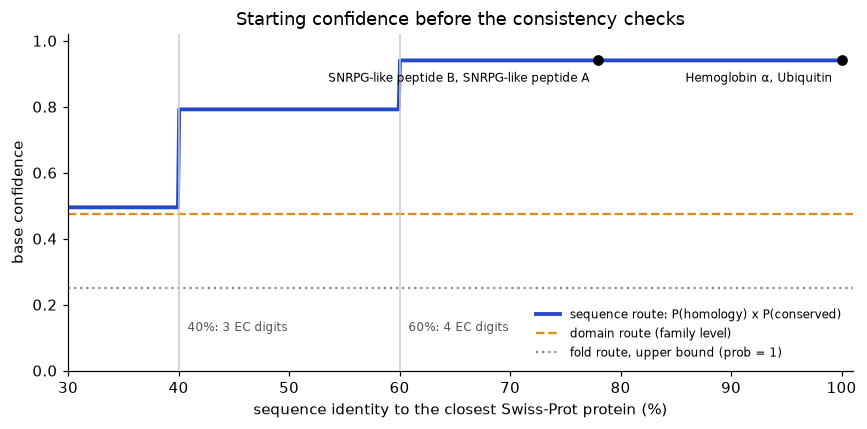

In [7]:
identities = np.linspace(30.01, 100, 600)
base_curve = [p_homology_seq(i, PARAMS) * p_conserved_seq(i, PARAMS) for i in identities]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(identities, base_curve, color="#2348c8", lw=2.5, label="sequence route: P(homology) x P(conserved)")
ax.axhline(PARAMS["dom_hom"] * PARAMS["dom_cons"], color="#e08a1e", ls="--", label="domain route (family level)")
ax.axhline(PARAMS["fold_cons"], color="#8a8f98", ls=":", label="fold route, upper bound (prob = 1)")
for x, text in ((40, "40%: 3 EC digits"), (60, "60%: 4 EC digits")):
    ax.axvline(x, color="#cccccc", lw=1)
    ax.text(x + 0.8, 0.12, text, fontsize=8, color="#555555")
points = {}
for p in EVIDENCE:
    hit = p["primary"].get("hit") if p["primary"]["ran"] else None
    if hit and hit["passed"]:
        points.setdefault(round(hit["identity"], 1), []).append(p["name"])
for identity, protein_names in points.items():
    y = p_homology_seq(identity, PARAMS) * p_conserved_seq(identity, PARAMS)
    ax.scatter(identity, y, color="black", zorder=3)
    ax.annotate(", ".join(protein_names), (identity, y), textcoords="offset points", xytext=(-6, -14), fontsize=8, ha="right")
ax.set(xlabel="sequence identity to the closest Swiss-Prot protein (%)", ylabel="base confidence", ylim=(0, 1.02), xlim=(30, 101))
ax.legend(loc="lower right", fontsize=8, frameon=False)
ax.set_title("Starting confidence before the consistency checks")
plt.tight_layout()
plt.show()

## 8. Predictions

In [8]:
RESULTS = [(p, predict(p)) for p in EVIDENCE]

def summary_row(p, r):
    return {
        "Protein": p["name"],
        "Predicted function": r["function"],
        "Specificity": r["specificity"],
        "Base": "" if r["base"] is None else f"{r['base']:.2f}",
        "Confidence": "" if r["score"] is None else f"{r['score']:.2f}",
        "Band": r["band"],
        **{k.capitalize(): v for k, v in r["support"].items()},
    }

display(pd.DataFrame([summary_row(p, r) for p, r in RESULTS]).set_index("Protein"))

,Predicted function,Specificity,Base,Confidence,Band,Primary,Secondary,Tertiary,Quaternary
Protein,,,,,,,,,
Hemoglobin α,Hemoglobin subunit alpha,specific protein,0.94,0.97,high,supports,supports,not run,supports
Ubiquitin,Ubiquitin,specific protein,0.94,0.97,high,supports,supports,not run,supports
SNRPG-like peptide B,Small nuclear ribonucleoprotein G,specific protein,0.94,0.96,high,supports,supports,not run,not run
SNRPG-like peptide A,Small nuclear ribonucleoprotein G,specific protein,0.94,0.94,high,supports,not run,not run,not run
AIG1-like protein,FAR-17a/AIG1-like protein family (Pfam PF04750),protein family,0.47,0.47,low,supports,not run,not run,not run
Unknown sequence,Function not determined,none,,,undetermined,neutral,neutral,not run,not run
Cytochrome c,Function not determined,none,,,undetermined,not run,not run,neutral,not run


### Step-by-step explanation for each protein
This is the same reasoning the web app will show under *"How this verdict was reached"*.

In [9]:
def explain(p, r):
    lines = [f"### {p['name']} · {p['note']}", f"**Prediction:** {r['function']}  ·  specificity: {r['specificity']}"]
    if r["route"] is None and not p["primary"]["ran"]:
        lines.append("No route applied: the primary level did not run, and every route starts from it (route 3 needs its "
                     "homology link between the query and the protein whose structure was analysed). **Function not determined.**")
    elif r["route"] is None:
        lines.append("No route applied: no characterised Swiss-Prot homologue or protein domain passed the primary tests, "
                     "and no characterised structural match came from a reliable structure that shares the query's fold. "
                     "**Function not determined.**")
    else:
        lines.append(f"**Route {['sequence', 'domain', 'fold'].index(r['route']) + 1} ({r['route']}):** {r['basis']}.")
        lines.append("")
        lines.append("| Step | Evidence | Log-odds |")
        lines.append("|---|---|---|")
        for level, text, delta in r["steps"]:
            shown = f"{delta:+.2f}" if level != "base" else f"{delta:.2f} (start)"
            lines.append(f"| {level} | {text} | {shown} |")
        total = sum(d for _, _, d in r["steps"])
        lines.append(f"| **total** | σ({total:.2f}) | **{r['score']:.2f} → {r['band']}** |")
    if r["route"] == "sequence":
        quat = p["quaternary"]
        if quat.get("ran") and quat.get("analysed") == p["primary"]["hit"]["accession"]:
            context = []
            if quat.get("formula"):
                context.append(f"oligomeric state of the template: {quat['formula']} ({quat['assembly_type'].lower()}, {quat['status']})")
            context += [f"member of the {name} ({cpx}, {stoich})" for name, cpx, stoich in quat["complexes"]]
            if quat["go_mf"]:
                context.append("GO molecular function of the template: " + ", ".join(t for _, t in quat["go_mf"][:4]))
            if context:
                lines.append("")
                lines.append("**Biological context from the quaternary level:** " + "; ".join(context) + ".")
    display(Markdown("\n".join(lines)))

for p, r in RESULTS:
    explain(p, r)

### Hemoglobin α · app example, UniProt P69905
**Prediction:** Hemoglobin subunit alpha  ·  specificity: specific protein
**Route 1 (sequence):** closest Swiss-Prot protein P69905 (HBA_HUMAN), 100.0% identity over 100.0% of the query.

| Step | Evidence | Log-odds |
|---|---|---|
| base | P(homology) 0.99 x P(function conserved) 0.95 = 0.94 | 2.76 (start) |
| secondary | 96.8% agreement with 1BZ1_1 (125 residues) | +0.40 |
| quaternary | template assembly A4 is CONFIRMED | +0.40 |
| **total** | σ(3.56) | **0.97 → high** |

**Biological context from the quaternary level:** oligomeric state of the template: A4 (homomer, CONFIRMED); member of the Hemoglobin HbA complex (CPX-2158, A2B2); GO molecular function of the template: oxygen carrier activity, heme binding, iron ion binding, oxygen binding.

### Ubiquitin · app example, PDB 1UBQ
**Prediction:** Ubiquitin  ·  specificity: specific protein
**Route 1 (sequence):** closest Swiss-Prot protein Q865C5 (UBIQ_CAMDR), 100.0% identity over 100.0% of the query.

| Step | Evidence | Log-odds |
|---|---|---|
| base | P(homology) 0.99 x P(function conserved) 0.95 = 0.94 | 2.76 (start) |
| secondary | 98.2% agreement with 1FXT_2 (57 residues) | +0.40 |
| quaternary | template assembly A is SUPPORTED | +0.40 |
| **total** | σ(3.56) | **0.97 → high** |

**Biological context from the quaternary level:** oligomeric state of the template: A (monomer, SUPPORTED).

### SNRPG-like peptide B · test sequence, 53 aa
**Prediction:** Small nuclear ribonucleoprotein G  ·  specificity: specific protein
**Route 1 (sequence):** closest Swiss-Prot protein Q3ZBL0 (RUXG_BOVIN), 78.0% identity over 94.3% of the query.

| Step | Evidence | Log-odds |
|---|---|---|
| base | P(homology) 0.99 x P(function conserved) 0.95 = 0.94 | 2.76 (start) |
| secondary | 92.5% agreement with 4V98_8 (40 residues) | +0.40 |
| **total** | σ(3.16) | **0.96 → high** |

### SNRPG-like peptide A · test sequence, 50 aa
**Prediction:** Small nuclear ribonucleoprotein G  ·  specificity: specific protein
**Route 1 (sequence):** closest Swiss-Prot protein Q3ZBL0 (RUXG_BOVIN), 78.0% identity over 100.0% of the query.

| Step | Evidence | Log-odds |
|---|---|---|
| base | P(homology) 0.99 x P(function conserved) 0.95 = 0.94 | 2.76 (start) |
| **total** | σ(2.76) | **0.94 → high** |

### AIG1-like protein · test sequence, 184 aa
**Prediction:** FAR-17a/AIG1-like protein family (Pfam PF04750)  ·  specificity: protein family
**Route 2 (domain):** Pfam domain FAR-17a/AIG1-like protein (PF04750, E = 2.1e-31).

| Step | Evidence | Log-odds |
|---|---|---|
| base | P(homology) 0.95 x P(function conserved) 0.50 = 0.47 | -0.10 (start) |
| **total** | σ(-0.10) | **0.47 → low** |

### Unknown sequence · test sequence with no known relatives, 55 aa
**Prediction:** Function not determined  ·  specificity: none
No route applied: no characterised Swiss-Prot homologue or protein domain passed the primary tests, and no characterised structural match came from a reliable structure that shares the query's fold. **Function not determined.**

### Cytochrome c · the tertiary notebook's example (UniProt P99999), 105 aa
**Prediction:** Function not determined  ·  specificity: none
No route applied: the primary level did not run, and every route starts from it (route 3 needs its homology link between the query and the protein whose structure was analysed). **Function not determined.**

### Where each protein's confidence comes from
The bars show the starting log-odds (from P(homology) × P(conserved)) and each check's adjustment;
the dot is the final log-odds, and the number on the right is the final confidence.

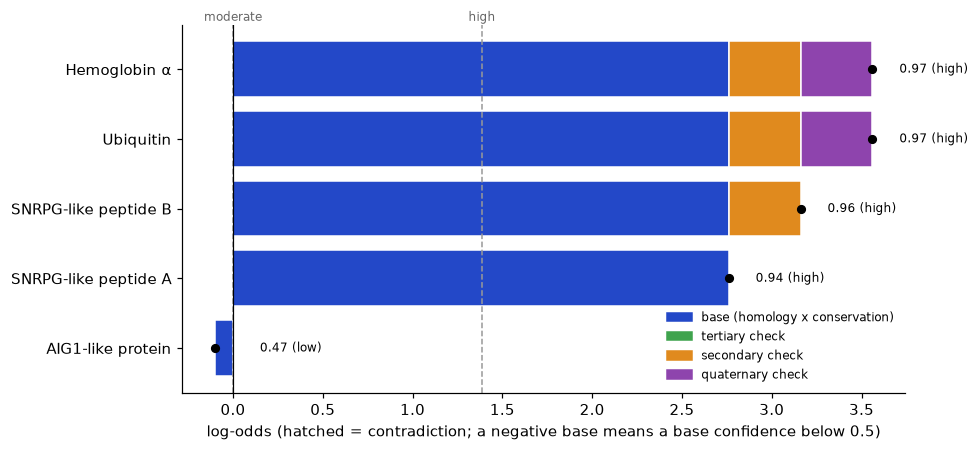

In [10]:
scored = [(p, r) for p, r in RESULTS if r["score"] is not None]
colours = {"base": "#2348c8", "tertiary": "#3fa34d", "secondary": "#e08a1e", "quaternary": "#8e44ad"}
fig, ax = plt.subplots(figsize=(9, 0.6 * len(scored) + 1.2))
for row, (p, r) in enumerate(scored):
    left_pos, left_neg = 0.0, 0.0
    for level, _, delta in r["steps"]:
        if delta == 0:
            continue
        hatch = "//" if delta < 0 and level != "base" else None  # a contradiction
        if delta > 0:
            ax.barh(row, delta, left=left_pos, color=colours[level], edgecolor="white")
            left_pos += delta
        else:
            ax.barh(row, delta, left=left_neg, color=colours[level], edgecolor="white", hatch=hatch)
            left_neg += delta
    total = sum(d for _, _, d in r["steps"])
    ax.plot(total, row, "ko", ms=5)
    ax.text(max(left_pos, total) + 0.15, row, f"{r['score']:.2f} ({r['band']})", va="center", fontsize=8)
for x, label in ((logit(PARAMS["high"]), "high"), (logit(PARAMS["moderate"]), "moderate")):
    ax.axvline(x, color="#999999", ls="--", lw=1)
    ax.text(x, 1.01, label, fontsize=8, color="#666666", ha="center", transform=ax.get_xaxis_transform())
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(range(len(scored)), [p["name"] for p, _ in scored])
ax.invert_yaxis()
ax.set_xlabel("log-odds (hatched = contradiction; a negative base means a base confidence below 0.5)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colours.values()]
ax.legend(handles, ["base (homology x conservation)", "tertiary check", "secondary check", "quaternary check"],
          fontsize=8, frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

## 9. Comparison with a naive weighted average
For contrast, the "obvious" approach: give each level a weight (sequence 0.40, domain 0.15, fold 0.20,
secondary 0.10, quaternary 0.15), score each from 0 to 1, and average over the levels that produced a result.

In [11]:
NAIVE_WEIGHTS = {"sequence": 0.40, "domain": 0.15, "fold": 0.20, "secondary": 0.10, "quaternary": 0.15}

def naive_weighted_average(ev):
    prim, sec, ter, quat = ev["primary"], ev["secondary"], ev["tertiary"], ev["quaternary"]
    scores = {}
    if prim["ran"]:
        hit = prim.get("hit")
        scores["sequence"] = 0.0 if not hit or not hit["passed"] else 1.0 if hit["identity"] >= 60 else 0.7 if hit["identity"] >= 40 else 0.4
        scores["domain"] = 1.0 if prim.get("domain") else 0.0
    if ter["ran"]:
        scores["fold"] = 1.0 if fold_is_significant(ter, PARAMS) else 0.0
    if sec["ran"] and sec.get("best") and sec["best"]["residues"] >= 20:
        a = sec["best"]["agreement"]
        scores["secondary"] = 1.0 if a >= 75 else 0.5 if a >= 60 else 0.0
    if quat["ran"] and quat.get("mode") == "homologue":
        scores["quaternary"] = {"CONFIRMED": 1.0, "SUPPORTED": 0.75, "PREDICTED": 0.4}.get(quat["status"], 0.0)
    if not scores:
        return None
    return sum(NAIVE_WEIGHTS[k] * v for k, v in scores.items()) / sum(NAIVE_WEIGHTS[k] for k in scores)

rows = []
for p, r in RESULTS:
    naive = naive_weighted_average(p)
    rows.append({"Protein": p["name"], "Specificity": r["specificity"],
                 "Naive weighted average": "" if naive is None else f"{naive:.2f}",
                 "Chain of evidence": "" if r["score"] is None else f"{r['score']:.2f}", "Band": r["band"]})
display(pd.DataFrame(rows).set_index("Protein"))

,Specificity,Naive weighted average,Chain of evidence,Band
Protein,,,,
Hemoglobin α,specific protein,1.00,0.97,high
Ubiquitin,specific protein,0.95,0.97,high
SNRPG-like peptide B,specific protein,1.00,0.96,high
SNRPG-like peptide A,specific protein,1.00,0.94,high
AIG1-like protein,protein family,0.27,0.47,low
Unknown sequence,none,0.00,,undetermined
Cytochrome c,none,1.00,,undetermined


**What the comparison shows**
* For well-characterised proteins (hemoglobin α, ubiquitin) both methods agree: everything points the same way.
* With **only the tertiary level** (cytochrome c), the naive average gives the maximum score (1.00) because the
  single available level gets all the weight. Yet the structure analysed is that of UniProt P99999, and without the
  primary level nothing links it to the query, so the chain of evidence makes no prediction. (With the primary level,
  cytochrome c would be predicted specifically and with high confidence by route 1.)
* For the **AIG1-like protein**, the naive average mixes a failed homology test (0) with a passing domain (1) into an
  uninterpretable 0.27, whereas the chain of evidence gives a *family-level* prediction with a confidence that
  reflects how often a family's function carries over.
* The naive approach has no notion of **specificity**, cannot express that agreement between dependent levels is
  expected, and lets contradictions only dilute rather than count against a prediction.

## 10. Sensitivity analysis: do the conclusions depend on the exact numbers?
Each parameter is changed on its own by −20% and +20%, and every protein is re-scored. A robust model should keep its bands.

In [12]:
SKIP = {"high", "moderate"}  # reporting thresholds, not model parameters

def perturbed(key, factor):
    P = dict(PARAMS)
    P[key] = PARAMS[key] * factor
    if key.startswith(("seq_hom", "cons_", "dom_", "fold_cons", "fold_prob", "fold_cov")):
        P[key] = min(P[key], 0.999)
    return P

baseline = {p["name"]: r for p, r in RESULTS}
records, ranges = [], {p["name"]: [] for p in EVIDENCE}
for key in PARAMS:
    if key in SKIP:
        continue
    for factor in (0.8, 1.2):
        P = perturbed(key, factor)
        changed = []
        for p in EVIDENCE:
            r = predict(p, P)
            if r["score"] is not None:
                ranges[p["name"]].append(r["score"])
            if r["band"] != baseline[p["name"]]["band"] or r["function"] != baseline[p["name"]]["function"]:
                changed.append(f"{p['name']}: {baseline[p['name']]['band']} → {r['band']}")
        records.append({"Parameter": key, "Change": f"{factor - 1:+.0%}", "Band or function changes": "; ".join(changed) or "none"})

table = pd.DataFrame(records)
stable = (table["Band or function changes"] == "none").sum()
print(f"Bands and functions unchanged in {stable} of {len(table)} single-parameter perturbations.")
display(table[table["Band or function changes"] != "none"].reset_index(drop=True))

Bands and functions unchanged in 35 of 38 single-parameter perturbations.


,Parameter,Change,Band or function changes
0,seq_hom_40,-20%,SNRPG-like peptide A: high → moderate
1,cons_60,-20%,SNRPG-like peptide A: high → moderate
2,dom_cons,+20%,AIG1-like protein: low → moderate


**Reading the result.** On the proteins above, no perturbation changes any *predicted function*, and the
few band changes all concern proteins supported by a single level of evidence that sit close to a band boundary
(for example, SNRPG-like peptide A, which has only the primary level). Proteins supported by several
consistent levels keep their band under every perturbation, which is exactly the behaviour expected of an
evidence-combination model: confidence that rests on several independent-looking checks is harder to overturn.

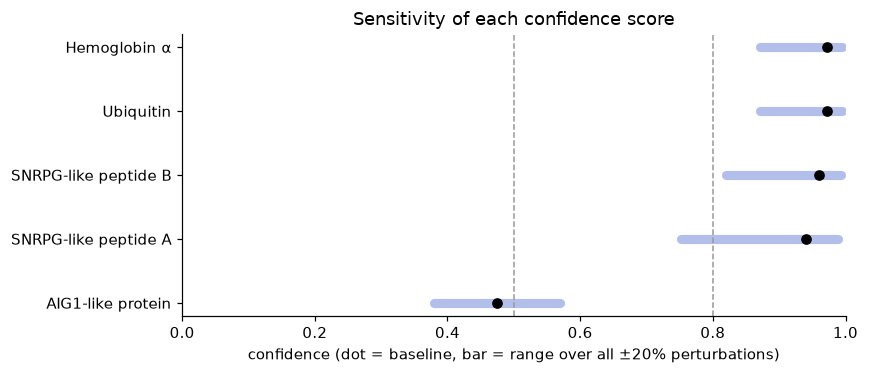

In [13]:
names = [p["name"] for p, r in RESULTS if r["score"] is not None]
fig, ax = plt.subplots(figsize=(8, 0.5 * len(names) + 1))
for row, name in enumerate(names):
    lo, hi = min(ranges[name]), max(ranges[name])
    ax.plot([lo, hi], [row, row], color="#2348c8", lw=6, alpha=0.35, solid_capstyle="round")
    ax.plot(baseline[name]["score"], row, "ko")
ax.axvline(PARAMS["high"], color="#999999", ls="--", lw=1)
ax.axvline(PARAMS["moderate"], color="#999999", ls="--", lw=1)
ax.set_yticks(range(len(names)), names)
ax.invert_yaxis()
ax.set(xlim=(0, 1), xlabel="confidence (dot = baseline, bar = range over all ±20% perturbations)")
ax.set_title("Sensitivity of each confidence score")
plt.tight_layout()
plt.show()

## 11. Ablation: what does each structural level add?
Hemoglobin α and ubiquitin have the primary, secondary and quaternary levels. Removing one level at a time shows how
much each contributes, and that the structural levels refine but do not carry the prediction.

In [14]:
def without(ev, level):
    copy = json.loads(json.dumps(ev))
    copy[level] = {"ran": False}
    return copy

rows = []
for p in EVIDENCE:
    if not all(p[level]["ran"] for level in ("primary", "secondary", "quaternary")):
        continue
    row = {"Protein": p["name"], "all levels that ran": f"{predict(p)['score']:.2f}"}
    for level in ("primary", "secondary", "quaternary"):
        r = predict(without(p, level))
        row[f"without {level}"] = "undetermined" if r["score"] is None else f"{r['score']:.2f} ({r['specificity']})"
    rows.append(row)
display(pd.DataFrame(rows).set_index("Protein"))

,all levels that ran,without primary,without secondary,without quaternary
Protein,,,,
Hemoglobin α,0.97,undetermined,0.96 (specific protein),0.96 (specific protein)
Ubiquitin,0.97,undetermined,0.96 (specific protein),0.96 (specific protein)


Removing the **primary** level leaves no prediction at all: sequence homology carries the specific function (and
the tertiary level needs the primary level's UniProt ID). Removing the secondary or quaternary level lowers the
confidence a little but never changes the prediction.

## 12. Limitations and how they are handled
* **Not calibrated.** The probabilities come from published studies (largely on enzymes) rather than from fitting on
  our own data, so the score ranks evidence transparently but is not a calibrated probability. A calibration would
  need a benchmark of proteins with known function, analysed with self-matches removed (hits ≥ 95% identity
  excluded), comparing predicted confidence with the observed fraction correct.
* **Dependence between levels** is handled by design: only the route provides the base probability, and the other
  levels give small, asymmetric adjustments rather than independent votes.
* **Top hit only.** The transfer uses the primary notebook's single best Swiss-Prot hit; for proteins identical across
  many species (e.g. ubiquitin) this may be an orthologue from another organism, which does not change the function.
* **Remote services.** The final primary notebook runs its fast local profile (DIAMOND, HMMER, ESM-2, ProtParam,
  UniProt). EBI BLASTp and InterProScan are optional: when the app's server is configured for them they refine the
  primary result in the background, and the prediction is recomputed when they finish, so it can still change in
  the minutes after it first appears.
* **Search sensitivity.** DIAMOND `--fast` is quicker than `--sensitive` (about 6.5× in the primary notebook's
  benchmark) and agreed with it on every benchmark case, but it can miss distant homologues; a protein whose only
  relatives are remote may then reach the domain route, or no route, where a sensitive search would have found the
  sequence route.
* **ESM-2 retrieval** is reported by the primary level against a 4-protein demonstration reference only; it is not
  used by the integration (a cosine similarity is not a probability, and four proteins cannot support a prediction).
* **Multidomain proteins.** A domain-level prediction names one family; proteins with several domains may combine functions.
* **Quaternary context** is reported for the template; it transfers reliably only for close homologues (≥ 30–40% identity).

## 13. Conclusion
The integration step predicts function by **annotation transfer from the best-supported template** and estimates
confidence as **P(homology) × P(function conserved)**, anchored to published relationships between sequence identity
and functional conservation. The secondary and quaternary levels then act as **consistency checks**, with
deliberately asymmetric adjustments because agreement between dependent levels is expected while contradictions
are informative; the tertiary level, which analyses the structure of the template itself, supplies the
structural route when that template is uncharacterised. Every prediction states its **specificity** (protein, family or fold), adds
**biological context** from the quaternary level (oligomeric state, complexes, GO terms), and shows each step of its
reasoning. On the proteins analysed here, no ±20% change of any parameter alters a predicted function, the model
degrades gracefully when levels are missing, and it avoids the over-confidence of a naive weighted average.

## References
1. Tian W, Skolnick J (2003). How well is enzyme function conserved as a function of pairwise sequence identity? *J Mol Biol* 333:863–882.
2. Rost B (1999). Twilight zone of protein sequence alignments. *Protein Eng* 12:85–94.
3. Rost B (2002). Enzyme function less conserved than anticipated. *J Mol Biol* 318:595–608.
4. Aloy P, Ceulemans H, Stark A, Russell RB (2003). The relationship between sequence and interaction divergence in proteins. *J Mol Biol* 332:989–998.
5. van Kempen M, Kim SS, Tumescheit C, et al. (2024). Fast and accurate protein structure search with Foldseek. *Nat Biotechnol* 42:243–246.
6. Jumper J, Evans R, Pritzel A, et al. (2021). Highly accurate protein structure prediction with AlphaFold. *Nature* 596:583–589.